# Banksy Benchmarking

- Creator: Sebastian Birk (sb75@sanger.ac.uk.com)
- Date of Creation: 12.07.2024
- Date of Last Modification: 06.04.2026 (by Sebastian Birk (sb75@sanger.ac.uk))

- Run this notebook in the banksy uv environment, installable from ```../../envs/banksy.sh```.
- The Banksy source code is available at https://github.com/prabhakarlab/Banksy (R) and https://github.com/prabhakarlab/Banksy_py (Python).
- The corresponding publication is "Singhal, V. et al. BANKSY unifies cell typing and tissue domain segmentation for scalable spatial omics data analysis. Nat. Genet. (2024) doi:10.1038/s41588-024-01664-3".
- This notebook follows the tutorial from https://github.com/prabhakarlab/Banksy_py/blob/main/slideseqv2_analysis.ipynb.

## 1. Setup

### 1.1 Import Libraries

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append("../../utils")

In [3]:
import warnings
import gc
import os
import time

import anndata as ad
import harmonypy
import matplotlib as mpl
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
import sklearn.metrics as skm
import squidpy as sq

from banksy.initialize_banksy import initialize_banksy
from banksy_utils.umap_pca import pca_umap
from banksy.embed_banksy import generate_banksy_matrix
from matplotlib import gridspec
from scib_metrics import ilisi_knn
from scib_metrics.nearest_neighbors import pynndescent
from scipy.spatial.distance import cdist
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

from analysis_utils import *

### 1.2 Define Config

In [58]:
method = 'banksy'

# General params
dataset_name = 'mmb0-1b_smb1-1b_1p'
batches = ['harmonised_merfish_mouse_brain_239-batch_batch82_shared_genes',
           'harmonised_starmap_plus_mouse_cns_batch15_shared_genes']
niche_key = 'tissue_region'
label_keys = [niche_key]
species = 'mouse'
n_neighs = 10
spot_sizes = {'MERFISH': 20,
              'STARmap PLUS': 100}
batch_key = 'batch'
n_pcs = None

# Banksy params
emb_key = 'banksy_latent'
max_m = 1 # use both mean and AFT
nbr_weight_decay = "scaled_gaussian" # can also choose "reciprocal", "uniform" or "ranked"
lambda_list = [1.0]
pca_dims = [20]
coord_keys = ('spatial_x', 'spatial_y', 'spatial')
resolutions = [0.7]  # clustering resolution for UMAP
pca_dims = [20]  # Dimensionality in which PCA reduces to
lambda_list = [1.0]  # list of lambda parameters

# Cluster params
latent_leiden_resolution = 1.11

### 1.3 Configure Paths

In [6]:
st_data_folder_path = '/lustre/scratch126/cellgen/lotfollahi/DATASETS'
st_data_silver_folder_path = f'{st_data_folder_path}/silver'
artifacts_folder_path = '/nfs/team361/sb75/stjepa-reproducibility/artifacts'
benchmarking_artifacts_folder_path = f'{artifacts_folder_path}/benchmarking'

### 1.4 Run Notebook Setup

In [7]:
warnings.filterwarnings("ignore", category=ResourceWarning)

In [8]:
plt.rcParams['font.size'] = 5
plt.rcParams['text.usetex'] = False
plt.rcParams['svg.fonttype'] = 'none'

In [9]:
# Improve reproducibility of UMAP and Leiden
os.environ['NUMBA_CPU_NAME'] = 'generic'

In [10]:
sc.settings.figdir = f'{benchmarking_artifacts_folder_path}/figures'

sc.settings.set_figure_params(
    dpi=300,
    dpi_save=300,
    figsize=(3, 2),
    facecolor='white',
    fontsize=7
)

In [11]:
os.makedirs(f'{benchmarking_artifacts_folder_path}/figures', exist_ok=True)
os.makedirs(f'{benchmarking_artifacts_folder_path}/results', exist_ok=True)
os.makedirs(f'{benchmarking_artifacts_folder_path}/{method}', exist_ok=True)

### 1.5 Define Functions

In [12]:
def make_large_cmap(n):
    base = plt.cm.get_cmap("turbo", n)   # or "hsv", "nipy_spectral"
    return [mcolors.to_hex(base(i)) for i in range(n)]

In [13]:
def mmd_comparable(adata, emb_key, batch_key, n_sub=2000, n_sigma=1000):
    # Normalize to zero mean, unit variance
    X = StandardScaler().fit_transform(adata.obsm[emb_key])
    
    # Compute sigma on normalized data
    idx = np.random.choice(len(X), min(n_sigma, len(X)), replace=False)
    sub = X[idx]
    dists = np.linalg.norm(sub[:, None] - sub[None, :], axis=2)
    sigma = np.median(dists[dists > 0])
    
    # Split by batch
    batches = adata.obs[batch_key].unique()
    mask0 = adata.obs[batch_key] == batches[0]
    mask1 = adata.obs[batch_key] == batches[1]
    b0, b1 = X[mask0], X[mask1]
    
    idx0 = np.random.choice(len(b0), min(n_sub, len(b0)), replace=False)
    idx1 = np.random.choice(len(b1), min(n_sub, len(b1)), replace=False)
    
    def rbf(A, B):
        d = np.linalg.norm(A[:, None] - B[None, :], axis=2)
        return np.exp(-d**2 / (2 * sigma**2))
    
    b0s, b1s = b0[idx0], b1[idx1]
    return rbf(b0s, b0s).mean() + rbf(b1s, b1s).mean() - 2 * rbf(b0s, b1s).mean()

In [14]:
def _combine_neighbor_graphs(adata: ad.AnnData,
                             n_neighs: int | None,
                             radius: float | None,
                             delaunay: bool,
                             include_self_loop: bool,
                             ) -> ad.AnnData:
    """
    Helper function to combine neighbor graphs computed using different
    methods.
    """
    if n_neighs is not None:
        # Compute knn spatial neighborhood graph
        sq.gr.spatial_neighbors(adata,
                                coord_type='generic',
                                spatial_key='spatial',
                                n_neighs=n_neighs,
                                set_diag=include_self_loop,
                                ) 
        knn_conn = adata.obsp['spatial_connectivities']  
    if radius is not None:
        # Compute spatial neighborhood graph with radius
        sq.gr.spatial_neighbors(adata,
                                coord_type='generic',
                                spatial_key='spatial',
                                radius=radius,
                                set_diag=include_self_loop,
                                )
        radius_conn = adata.obsp['spatial_connectivities'] 
        if n_neighs is not None:
            adata.obsp[
                'spatial_connectivities'] = knn_conn.multiply(
                    adata.obsp['spatial_connectivities'])
    if delaunay:
        # Compute spatial neighborhood graph with delaunay triangulation
        sq.gr.spatial_neighbors(adata,
                                coord_type='generic',
                                spatial_key='spatial',
                                delaunay=True,
                                set_diag=include_self_loop,
                                )
        if n_neighs is not None:
            adata.obsp[
                'spatial_connectivities'] = knn_conn.multiply(
                    adata.obsp['spatial_connectivities'])
        if radius is not None:
            adata.obsp[
                'spatial_connectivities'] = radius_conn.multiply(
                    adata.obsp['spatial_connectivities'])

    return adata


def construct_neighbor_graph(adata: ad.AnnData,
                             n_neighs: int | None = None,
                             radius: float | None = None,
                             delaunay: bool = True,
                             include_self_loop: bool = False,
                             batch_key: str | None = None,
                             compute_neighbor_counts: bool = False,
                             ) -> ad.AnnData:
    """
    Compute neighbor graph and optionally aggregate cell features across
    neighbors.

    Parameters
    ----------
    adata:
        AnnData object with spatial coordinates available in
        `adata.obsm['spatial']`.
    n_neighs:
        If specified, use `n_neighs` to compute the neighborhood graph.
        If 'radius' or 'delaunay' are also specified, an intersection
        neighborhood graph will be computed.
    radius:
        If specified, use `radius` to compute the neighborhood graph. If
        'n_neighs' or 'delaunay' are also specified, an intersection
        neighborhood graph will be computed.
    delaunay:
        If 'True', compute the neighborhood graph by delaunay
        triangulation. If 'n_neighs' or 'radius' are also specified, an
        intersection neighborhood graph will be computed.
    include_self_loop:
        If 'True', include cell itself in neighborhood graph.
    batch_key:
        Key in adata.obs where the batch is stored in case the AnnData
        contains multiple batches. This is important to specify if there
        are multiple batches in the AnnData to perform separate neighbor
        graph computation and then concatenate.
    compute_neighbor_counts:
        If 'True', aggregate counts across neighborhood and store in
        `adata.layers['X_neighborhood']`.

    Returns
    ----------
    adata:
        AnnData object with aggregated counts available in
        `adata.layers['X_neighborhood']`.
    """
    if batch_key is not None:
        # Get ordered batches
        first_idx = adata.obs.reset_index().groupby(batch_key).head(1).index
        batches = adata.obs.iloc[first_idx][batch_key].tolist()
        adata_batch_list = []

        for batch in batches:
            print(f"\nProcessing batch {batch}...")
            print("Loading data...")
            adata_batch = adata[adata.obs[batch_key] == batch]

            print("Computing spatial neighborhood graph...")
            adata_batch = _combine_neighbor_graphs(
                adata_batch,
                n_neighs,
                radius,
                delaunay,
                include_self_loop)
            adata_batch_list.append(adata_batch)

        # Block-diagonal concatenate graphs (disconnected components)
        adata.obsp['spatial_connectivities'] = sp.block_diag(
            [a.obsp['spatial_connectivities'] for a in adata_batch_list],
            format="csr",
        )    
    else:
        adata = _combine_neighbor_graphs(
            adata,
            n_neighs,
            radius,
            delaunay,
            include_self_loop)           
    
    if compute_neighbor_counts:
        adata.layers['X_neighborhood'] = (
            adata.obsp['spatial_connectivities'].T @ adata.X)

    return adata

## 2. Analysis

### 2.1 Retrieve Embeddings

In [15]:
# Load adata batches and concatenate for inference
adata_list = []

for subdir, _, files in os.walk(f'{st_data_silver_folder_path}/{dataset_name}'):
    for file_idx, file in enumerate(files):
        if file.endswith('.h5ad') & any(batch in file for batch in batches):
            file_path = os.path.join(subdir, file)
            adata = sc.read_h5ad(file_path)

            print(file)

            if file == 'harmonised_merfish_mouse_brain_239-batch_batch82_shared_genes.h5ad':
                adata.obs[niche_key] = adata.obs['ccf_region_name']
                adata.obs[batch_key] = file.replace(',h5ad', '')
            elif file == 'harmonised_starmap_plus_mouse_cns_batch15_shared_genes.h5ad':
                adata.obs[niche_key] = adata.obs['Sub_molecular_tissue_region']
                adata.obs[batch_key] = file.replace('.h5ad', '')                

            # Filter cells without niche labels
            adata = adata[~adata.obs[niche_key].isna()]
            print(adata.obs.columns)
            adata_list.append(adata)

adata = ad.concat(adata_list, join='outer', index_unique=None)

harmonised_merfish_mouse_brain_239-batch_batch82_shared_genes.h5ad
Index(['donor_id', 'brain_section_label', 'major_brain_region',
       'ccf_region_name', 'cell_type', 'cell_id', 'n_genes',
       'nichecompass_latent_cluster', 'tissue_region', 'batch'],
      dtype='object')
harmonised_starmap_plus_mouse_cns_batch15_shared_genes.h5ad
Index(['Main_molecular_cell_type', 'Sub_molecular_cell_type',
       'Main_molecular_tissue_region', 'Sub_molecular_tissue_region',
       'Molecular_spatial_cell_type', 'dataset', 'cell_type',
       'cell_type_ontology_term_id', 'n_genes', 'cell_id',
       'nichecompass_latent_cluster', 'tissue_region', 'batch'],
      dtype='object')


/tmp/ipykernel_3831263/3628020456.py:24: UserWarning: Only some AnnData objects have `.raw` attribute, not concatenating `.raw` attributes.
  adata = ad.concat(adata_list, join='outer', index_unique=None)


In [16]:
print('Computing spatial neighborhood...')
# Construct neighbor graph (overwrite novae graph which is not symmetric)
adata = construct_neighbor_graph(
    adata,
    n_neighs=n_neighs,
    batch_key=batch_key,
    radius=None,
    delaunay=None,
    include_self_loop=True,
    compute_neighbor_counts=False)

Computing spatial neighborhood...

Processing batch harmonised_merfish_mouse_brain_239-batch_batch82_shared_genes.h5ad...
Loading data...
Computing spatial neighborhood graph...
INFO     Creating graph using `generic` coordinates and `None` transform and `1` libraries.                        

Processing batch harmonised_starmap_plus_mouse_cns_batch15_shared_genes...
Loading data...
Computing spatial neighborhood graph...
INFO     Creating graph using `generic` coordinates and `None` transform and `1` libraries.                        


/nfs/team361/sb75/.venvs/banksy/lib/python3.12/site-packages/squidpy/gr/_utils.py:194: ImplicitModificationWarning: Setting element `.obsp['spatial_connectivities']` of view, initializing view as actual.
  obj[key] = data
/nfs/team361/sb75/.venvs/banksy/lib/python3.12/site-packages/squidpy/gr/_utils.py:194: ImplicitModificationWarning: Setting element `.obsp['spatial_connectivities']` of view, initializing view as actual.
  obj[key] = data


In [17]:
adata.obs["spatial_x"] = adata.obsm['spatial'][:, 0]
adata.obs["spatial_y"] = adata.obsm['spatial'][:, 1]


Median distance to closest cell = 27.100472320923743

---- Ran median_dist_to_nearest_neighbour in 0.47 s ----

---- Ran generate_spatial_distance_graph in 0.93 s ----

---- Ran row_normalize in 0.13 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 1.99 s ----

----- Plotting Edge Histograms for m = 0 -----

Edge weights (distances between cells): median = 52.09770676838649, mode = 24.447096944984636

---- Ran plot_edge_histogram in 0.03 s ----


Edge weights (weights between cells): median = 0.0883885979060727, mode = 0.06005690181201036

---- Ran plot_edge_histogram in 0.31 s ----

---- Ran generate_spatial_distance_graph in 0.69 s ----

---- Ran theta_from_spatial_graph in 0.35 s ----

---- Ran row_normalize in 0.13 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 2.00 s ----

----- Plotting Edge Histograms for m = 1 -----

Edge weights (distances between cells): median = 67.7530530232352, mode = 37.23618856530797

---- Ran plot_edge_histogram in 0.04 s ----



/nfs/team361/sb75/.venvs/banksy/lib/python3.12/site-packages/matplotlib/cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/nfs/team361/sb75/.venvs/banksy/lib/python3.12/site-packages/numpy/lib/_histograms_impl.py:853: ComplexWarning: Casting complex values to real discards the imaginary part
  indices = f_indices.astype(np.intp)
/nfs/team361/sb75/.venvs/banksy/lib/python3.12/site-packages/matplotlib/axes/_axes.py:7135: ComplexWarning: Casting complex values to real discards the imaginary part
  bins = np.array(bins, float)  # causes problems if float16
/nfs/team361/sb75/.venvs/banksy/lib/python3.12/site-packages/matplotlib/cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)



Edge weights (weights between cells): median = (0.00010873429958570575-0.0192478567957134j), mode = 0.013368184478476652

---- Ran plot_edge_histogram in 0.12 s ----

----- Plotting Weights Graph -----
Maximum weight: 0.3160889547864687

---- Ran plot_graph_weights in 4.78 s ----

Maximum weight: (0.14039407165697465+0.009606080050122154j)

---- Ran plot_graph_weights in 9.21 s ----

----- Plotting theta Graph -----


/nfs/team361/sb75/.venvs/banksy/lib/python3.12/site-packages/matplotlib/collections.py:430: ComplexWarning: Casting complex values to real discards the imaginary part
  renderer.draw_path_collection(


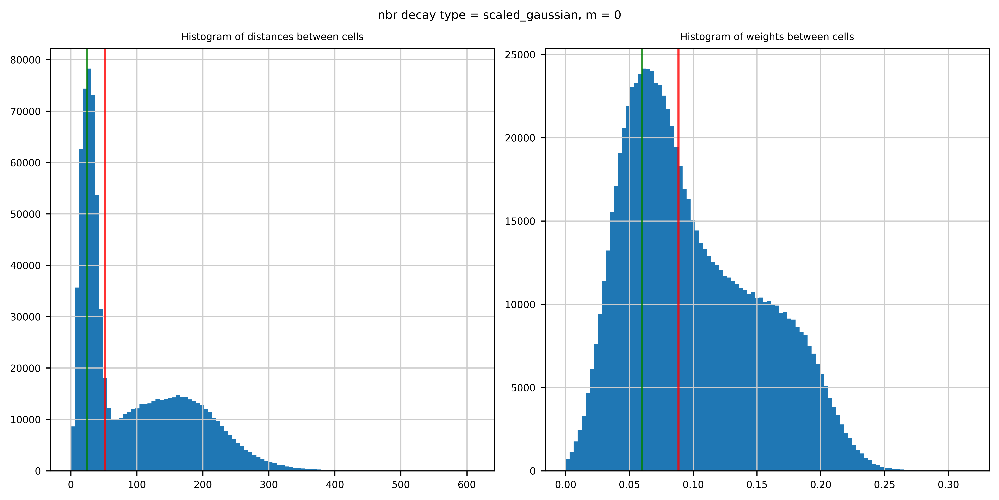

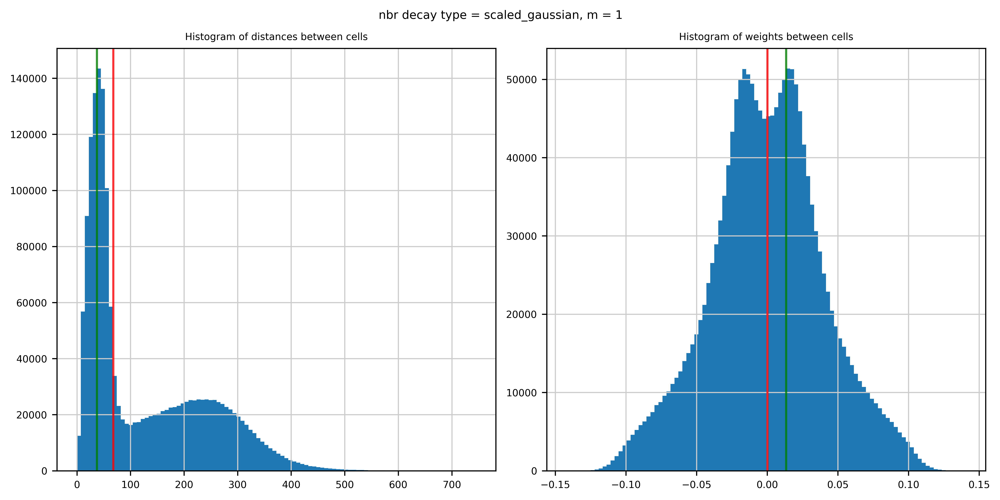

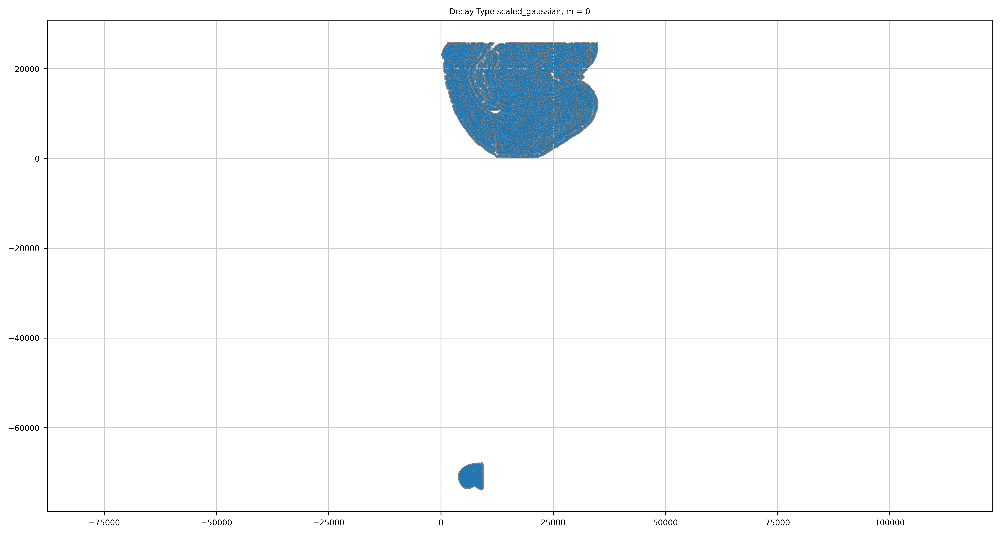

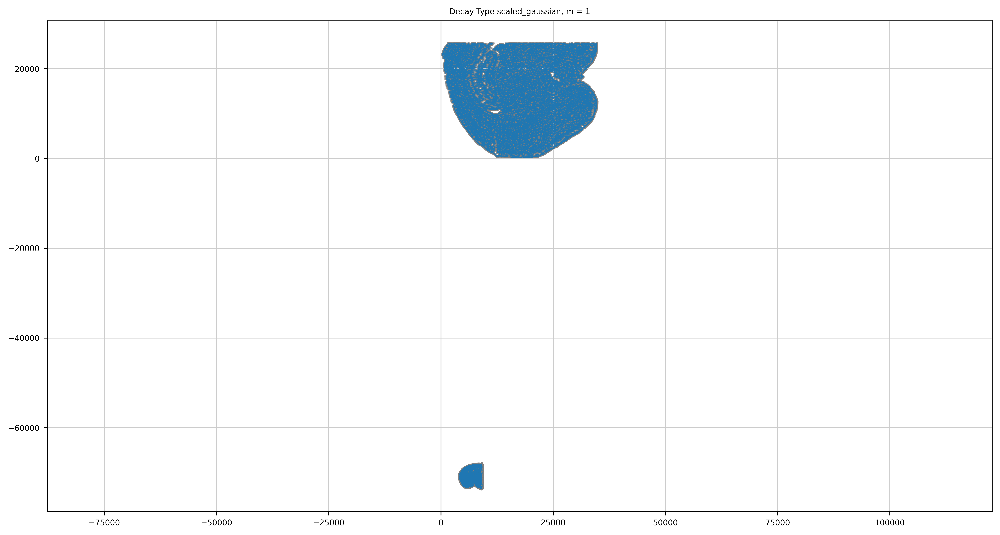

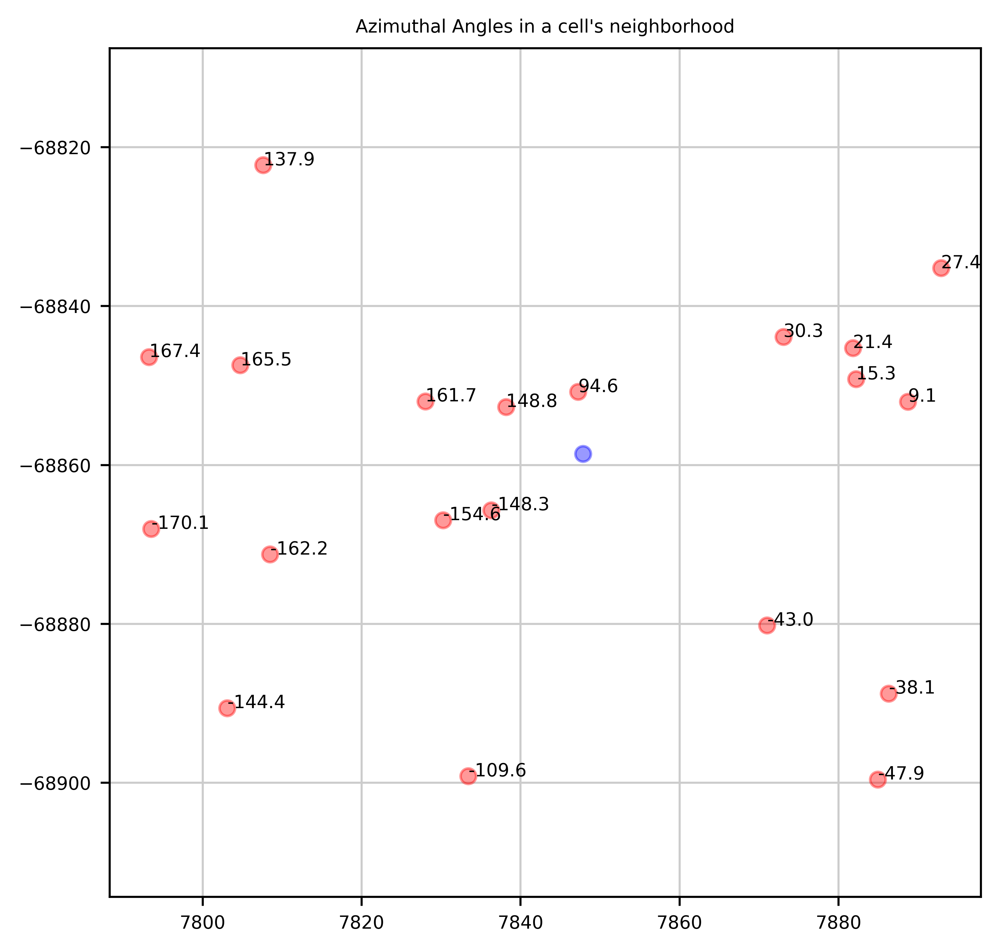

In [18]:
banksy_dict = initialize_banksy(
    adata,
    coord_keys,
    n_neighs,
    nbr_weight_decay=nbr_weight_decay,
    max_m=max_m,
    plt_edge_hist=True,
    plt_nbr_weights=True,
    plt_agf_angles=False, # takes long time to plot
    plt_theta=True,
)

In [19]:
banksy_dict, banksy_matrix = generate_banksy_matrix(adata,
                                                    banksy_dict,
                                                    lambda_list,
                                                    max_m)

Runtime Apr-06-2026-20-59

431 genes to be analysed:
Gene List:
Index(['A2m', 'Abcc9', 'Abi3bp', 'Acta2', 'Adcyap1', 'Adgrg2', 'Adgrg6',
       'Adora1', 'Adora2a', 'Adra1b',
       ...
       'Ung', 'Vcan', 'Vgll3', 'Vipr2', 'Vwc2', 'Vwc2l', 'Wif1', 'Wnt4',
       'Zfhx4', 'Zic1'],
      dtype='object', name='gene_name', length=431)

Check if X contains only finite (non-NAN) values
Decay Type: scaled_gaussian
Weights Object: {'weights': {0: <Compressed Sparse Row sparse matrix of dtype 'float64'
	with 857040 stored elements and shape (85704, 85704)>, 1: <Compressed Sparse Row sparse matrix of dtype 'complex128'
	with 1714080 stored elements and shape (85704, 85704)>}}

Nbr matrix | Mean: 0.2 | Std: 0.8
Size of Nbr | Shape: (85704, 431)
Top 3 entries of Nbr Mat:

[[0.         0.47333579 0.        ]
 [0.         0.         0.        ]
 [0.         0.         0.        ]]

AGF matrix | Mean: 0.1 | Std: 0.32
Size of AGF mat (m = 1) | Shape: (85704, 431)
Top entries of AGF:
[[0.03325178 0.

In [20]:
pca_umap(banksy_dict,
         pca_dims = pca_dims,
         add_umap = True,
         plt_remaining_var = False,
         )

Current decay types: ['scaled_gaussian']

Reducing dims of dataset in (Index = scaled_gaussian, lambda = 1.0)

Setting the total number of PC = 20
Original shape of matrix: (85704, 1293)
Reduced shape of matrix: (85704, 20)
------------------------------------------------------------
min_value = -18.521333795373277, mean = -4.515557783629155e-15, max = 44.79688891345226

Conducting UMAP and adding embeddings to adata.obsm["reduced_pc_20_umap"]
UMAP embedding
------------------------------------------------------------
shape: (85704, 2)


AxisArrays with keys: reduced_pc_20, reduced_pc_20_umap


In [21]:
adata.obsm[emb_key] = banksy_dict[nbr_weight_decay][lambda_list[0]]["adata"].obsm["reduced_pc_20"]

In [22]:
x = adata.obsm[emb_key].astype('float64')
harmony_out = harmonypy.run_harmony(x, adata.obs, batch_key)
adata.obsm[f'{emb_key}_harmony'] = harmony_out.Z_corr

2026-04-06 21:00:31,785 - harmonypy - INFO - Running Harmony (PyTorch on cuda)
2026-04-06 21:00:31,787 - harmonypy - INFO -   Parameters:
2026-04-06 21:00:31,788 - harmonypy - INFO -     max_iter_harmony: 10
2026-04-06 21:00:31,789 - harmonypy - INFO -     max_iter_kmeans: 20
2026-04-06 21:00:31,790 - harmonypy - INFO -     epsilon_cluster: 1e-05
2026-04-06 21:00:31,790 - harmonypy - INFO -     epsilon_harmony: 0.0001
2026-04-06 21:00:31,791 - harmonypy - INFO -     nclust: 100
2026-04-06 21:00:31,792 - harmonypy - INFO -     block_size: 0.05
2026-04-06 21:00:31,793 - harmonypy - INFO -     lamb: [1. 1.]
2026-04-06 21:00:31,793 - harmonypy - INFO -     theta: [2. 2.]
2026-04-06 21:00:31,793 - harmonypy - INFO -     sigma: [0.1 0.1 0.1 0.1 0.1]...
2026-04-06 21:00:31,794 - harmonypy - INFO -     verbose: True
2026-04-06 21:00:31,794 - harmonypy - INFO -     random_state: 0
2026-04-06 21:00:31,794 - harmonypy - INFO -   Data: 20 PCs × 85704 cells
2026-04-06 21:00:31,795 - harmonypy - INF

In [23]:
# Write to disk
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_embedded.h5ad')

### 2.2 Visualize UMAP

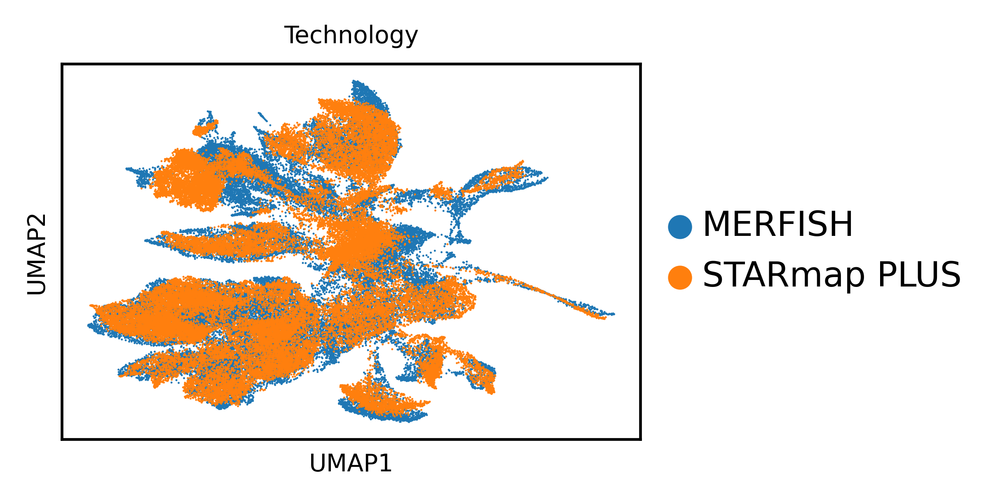

/tmp/ipykernel_3831263/3447051690.py:2: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  base = plt.cm.get_cmap("turbo", n)   # or "hsv", "nipy_spectral"


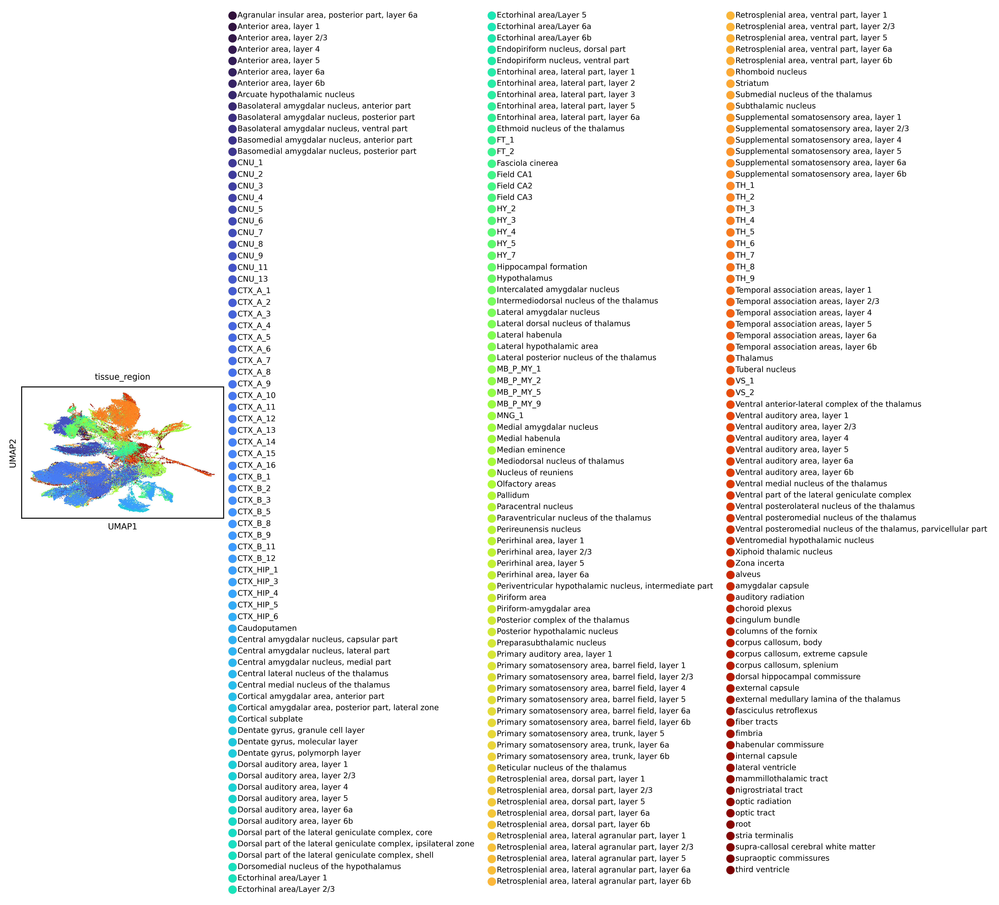

In [24]:
sc.pp.neighbors(adata, n_neighbors=15, use_rep=f'{emb_key}_harmony',
                n_pcs=n_pcs, key_added=f'{emb_key}_harmony')
sc.tl.umap(adata, neighbors_key=f'{emb_key}_harmony')

n_pcs_string = f"_{n_pcs}_pcs" if n_pcs else ""
categories = adata.obs[batch_key].cat.categories.tolist()
assert len(categories) == 2, "Expected exactly 2 categories for batch_key"
rename = dict(zip(sorted(categories), ["MERFISH", "STARmap PLUS"]))
adata.obs[batch_key] = adata.obs[batch_key].map(rename).astype("category")

sc.pl.umap(
    adata,
    color=batch_key,
    title="Technology",
    legend_loc="right margin",
    legend_fontsize=10,
    show=False,
)
for collection in plt.gca().collections:
    collection.set_rasterized(True)
plt.savefig(
    f"{benchmarking_artifacts_folder_path}/banksy/{dataset_name}_{emb_key}_umap_by_{batch_key}{n_pcs_string}.svg",
    format="svg", bbox_inches="tight"
)
plt.show()
plt.close()

for label_key in label_keys:
    n_cats = adata.obs[label_key].nunique()
    palette = make_large_cmap(n_cats)
    sc.pl.umap(adata, color=label_key, palette=palette, show=False)
    for collection in plt.gca().collections:
        collection.set_rasterized(True)
    plt.savefig(
        f"{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_{emb_key}_umap_by_{label_key}{n_pcs_string}.svg",
        format="svg", bbox_inches="tight"
    )
    plt.show()
    plt.close()

In [25]:
# Write to disk
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_embedded.h5ad')

### 2.3 Visualize Niches

In [62]:
adata = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_embedded.h5ad')

In [63]:
### Plot embedding-based clusters
latent_cluster_key = f"{f'{emb_key}_harmony'}_clusters_res_{latent_leiden_resolution}"

sc.tl.leiden(adata,
             neighbors_key=f'{emb_key}_harmony',
             key_added=latent_cluster_key,
             resolution=latent_leiden_resolution,
             flavor="igraph",
             n_iterations=2)

In [64]:
print(adata.obs[latent_cluster_key].nunique())
print(adata.obs[latent_cluster_key].value_counts())

30
banksy_latent_harmony_clusters_res_1.11
9     7083
22    7067
21    5589
14    5076
4     5045
0     4906
2     4898
16    4501
7     4346
27    3916
17    3863
15    3816
28    3050
3     2988
8     2465
11    2372
26    1896
20    1779
24    1447
6     1353
5     1317
29    1213
18    1162
13    1132
25    1077
10     859
23     841
19     531
1       79
12      37
Name: count, dtype: int64


In [65]:
# Write to disk
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_embedded_clustered.h5ad')

/tmp/ipykernel_3831263/93824751.py:4: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/nfs/team361/sb75/.venvs/banksy/lib/python3.12/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


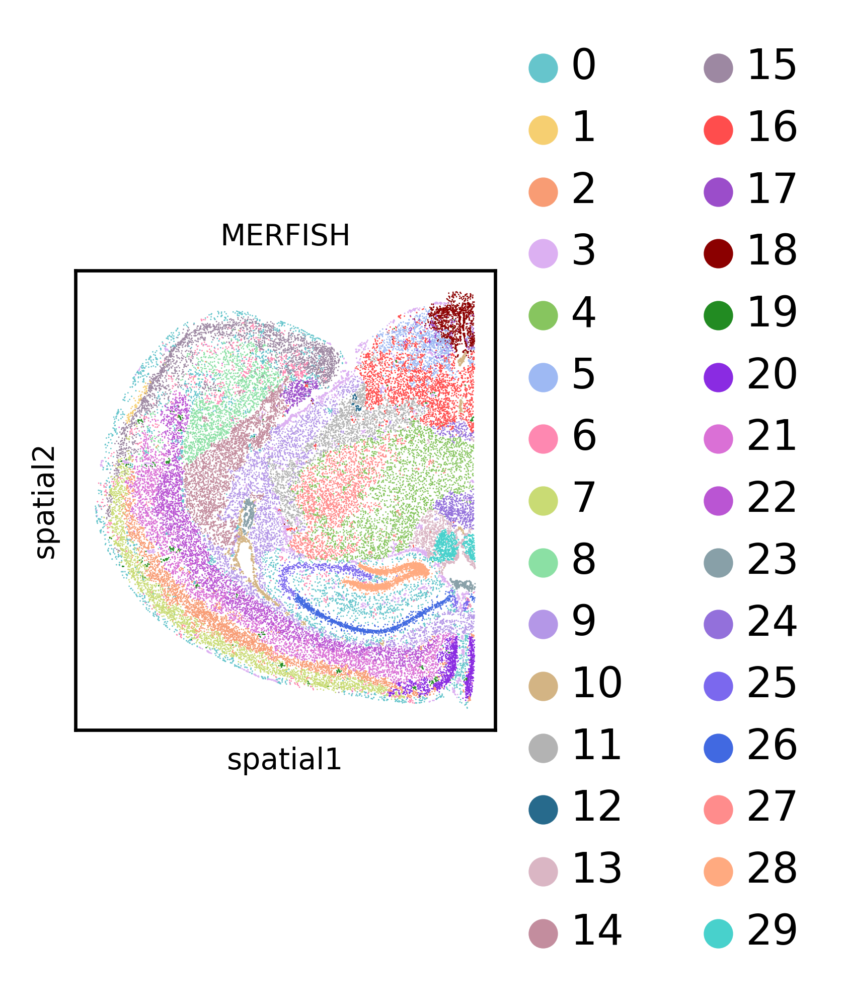

/tmp/ipykernel_3831263/93824751.py:4: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/nfs/team361/sb75/.venvs/banksy/lib/python3.12/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


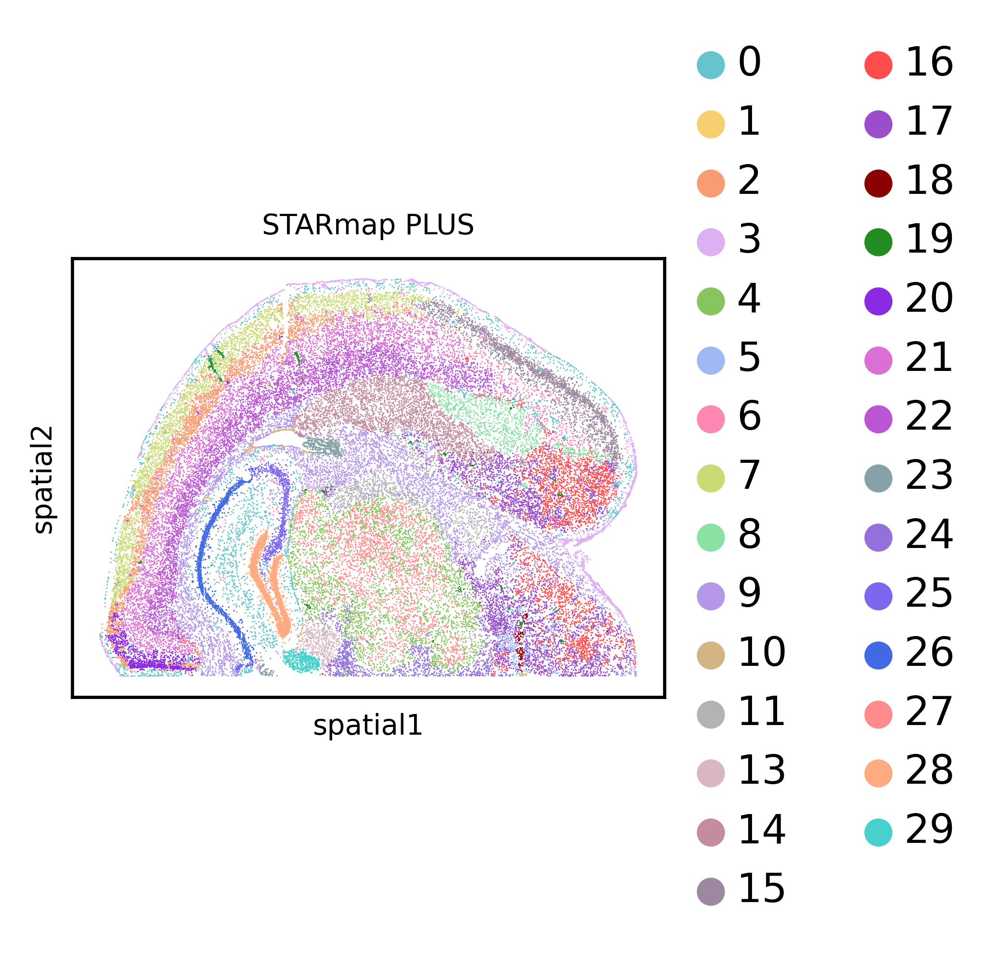

In [66]:
samples = adata.obs[batch_key].unique().tolist()
for sample in samples:
    adata_sample = adata[adata.obs[batch_key] == sample]
    sc.pl.spatial(
        adata_sample,
        color=latent_cluster_key,
        palette=custom_palette,
        spot_size=spot_sizes[sample],
        title=sample,
        legend_loc="right margin",
        legend_fontsize=10,
        show=False,
    )

    fig = plt.gcf()
    for ax in fig.axes:
        for child in ax.get_children():
            if isinstance(child, mpl.image.AxesImage):
                child.set_rasterized(True)
        for collection in ax.collections:
            collection.set_rasterized(True)

    plt.savefig(
        f"{benchmarking_artifacts_folder_path}/{method}/tissue_{sample}_by_{latent_cluster_key}.svg",
        format="svg", bbox_inches="tight"
    )
    plt.show()
    plt.close()

### 2.4 Compute Metrics

In [67]:
# Compute average cosine similarity of embeddings
X = adata.obsm[f'{emb_key}_harmony']
X = X / np.linalg.norm(X, axis=1, keepdims=True)
n = X.shape[0]
S = X.sum(axis=0)
avg_cos_sim = (S @ S - n) / (n * (n - 1))
print(f"{f'{emb_key}_harmony'} average cosine similarity: {avg_cos_sim}")

cos_sim_result = pd.DataFrame([{
    "emb_key": f'{emb_key}_harmony',
    "avg_cosine_similarity": avg_cos_sim,
}])

out_path = (
    f"{benchmarking_artifacts_folder_path}/{method}/"
    f"{dataset_name}_{f'{emb_key}_harmony'}_avg_cosine_similarity.csv"
)
cos_sim_result.to_csv(out_path, index=False)
print(f"Saved → {out_path}")

banksy_latent_harmony average cosine similarity: 0.00618298165500164
Saved → /nfs/team361/sb75/stjepa-reproducibility/artifacts/benchmarking/banksy/mmb0-1b_smb1-1b_1p_banksy_latent_harmony_avg_cosine_similarity.csv


In [68]:
# Compute NMI and ARI with region annotations
results = []
for region_key in ["Sub_molecular_tissue_region", "ccf_region_name"]:
    mask = adata.obs[region_key].notna()
    labels_true = adata.obs.loc[mask, region_key]
    labels_pred = adata.obs.loc[mask, latent_cluster_key]
    nmi = skm.normalized_mutual_info_score(labels_true, labels_pred)
    ari = skm.adjusted_rand_score(labels_true, labels_pred)
    print(f"NMI ({region_key}): {nmi:.4f}")
    print(f"ARI ({region_key}): {ari:.4f}")
    results.append({"region_key": region_key, "NMI": nmi, "ARI": ari})

df = pd.DataFrame(results)
df.to_csv(
    f"{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_{latent_cluster_key}_niche_identification_metrics.csv",
    index=False
)

NMI (Sub_molecular_tissue_region): 0.6814
ARI (Sub_molecular_tissue_region): 0.4043
NMI (ccf_region_name): 0.5876
ARI (ccf_region_name): 0.2328


In [69]:
# Compute batch integration metrics
results = []

# iLISI
batch = adata.obs[batch_key].values
knn = pynndescent(adata.obsm[f'{emb_key}_harmony'], n_neighbors=90)
ilisi = float(np.mean(ilisi_knn(knn, batch)))
print(f"iLISI: {ilisi:.4f}")
results.append({"metric": "iLISI", "score": ilisi})

# ASW
asw = silhouette_score(
    adata.obsm[f'{emb_key}_harmony'],
    adata.obs["batch"],
    metric="euclidean",
    sample_size=10000
)
print(f"ASW batch: {asw:.4f}")
results.append({"metric": "ASW", "score": asw})

# MMD
mmd_score = mmd_comparable(adata, f'{emb_key}_harmony', batch_key)
print(f"MMD: {mmd_score:.4f}")
results.append({"metric": "MMD", "score": mmd_score})

# Save
df = pd.DataFrame(results)
df.to_csv(
    f"{benchmarking_artifacts_folder_path}/{method}/{dataset_name}_{f'{emb_key}_harmony'}_batch_integration_metrics.csv",
    index=False
)

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


iLISI: 0.1770
ASW batch: 0.0020
MMD: 0.0023


In [70]:
# --- Config -----------------------------------------------------------
latent_leiden_resolution = 1.0
N_STEPS   = 4      # points above and below base resolution
STEP_SIZE = 0.1
MIN_RES   = 0.1    # Leiden resolution must be > 0

region_keys = ["Sub_molecular_tissue_region", "ccf_region_name"]

# Build resolution grid: N_STEPS below and above base, clamped to MIN_RES
# Use integer steps to avoid float accumulation errors in np.arange
base_int = round(latent_leiden_resolution / STEP_SIZE)  # e.g. 1.0/0.1 -> 10
resolutions = [
    round(step * STEP_SIZE, 1)
    for step in range(base_int - N_STEPS, base_int + N_STEPS + 1)
    if step * STEP_SIZE >= MIN_RES
]

# --- Sweep ------------------------------------------------------------
all_results = []

for res in resolutions:
    cluster_key = f"{f'{emb_key}_harmony'}_clusters_res_{res}"

    # Leiden clustering
    try:
        rsc.tl.leiden(adata,
                      neighbors_key=f'{emb_key}_harmony',
                      key_added=cluster_key,
                      resolution=res,
                      flavor="igraph",
                      n_iterations=2)
    except NameError:
        sc.tl.leiden(adata,
                     neighbors_key=f'{emb_key}_harmony',
                     key_added=cluster_key,
                     resolution=res,
                     flavor="igraph",
                     n_iterations=2)

    n_clusters = adata.obs[cluster_key].nunique()
    print(f"\n── Resolution {res:.1f}  ({n_clusters} clusters) ──")

    for region_key in region_keys:
        mask        = adata.obs[region_key].notna()
        labels_true = adata.obs.loc[mask, region_key]
        labels_pred = adata.obs.loc[mask, cluster_key]

        nmi = skm.normalized_mutual_info_score(labels_true, labels_pred)
        ari = skm.adjusted_rand_score(labels_true, labels_pred)
        print(f"  {region_key:40s}  NMI={nmi:.4f}  ARI={ari:.4f}")

        all_results.append({
            "resolution": res,
            "n_clusters": n_clusters,
            "region_key": region_key,
            "NMI":        nmi,
            "ARI":        ari,
        })

# --- Save -------------------------------------------------------------
df = pd.DataFrame(all_results)

# Canonical column order
df = df[["resolution", "n_clusters", "region_key", "NMI", "ARI"]]

out_path = (
    f"{benchmarking_artifacts_folder_path}/{method}/"
    f"{dataset_name}_{f'{emb_key}_harmony'}_niche_identification_metrics_res_sweep.csv"
)
df.to_csv(out_path, index=False)
print(f"\nSaved {len(df)} rows → {out_path}")


── Resolution 0.6  (23 clusters) ──
  Sub_molecular_tissue_region               NMI=0.6782  ARI=0.4126
  ccf_region_name                           NMI=0.5771  ARI=0.2015

── Resolution 0.7  (23 clusters) ──
  Sub_molecular_tissue_region               NMI=0.6789  ARI=0.4153
  ccf_region_name                           NMI=0.5747  ARI=0.1998

── Resolution 0.8  (24 clusters) ──
  Sub_molecular_tissue_region               NMI=0.6799  ARI=0.4158
  ccf_region_name                           NMI=0.5786  ARI=0.2024

── Resolution 0.9  (24 clusters) ──
  Sub_molecular_tissue_region               NMI=0.6866  ARI=0.3988
  ccf_region_name                           NMI=0.5807  ARI=0.2118

── Resolution 1.0  (26 clusters) ──
  Sub_molecular_tissue_region               NMI=0.6761  ARI=0.3865
  ccf_region_name                           NMI=0.5798  ARI=0.2115

── Resolution 1.1  (31 clusters) ──
  Sub_molecular_tissue_region               NMI=0.6796  ARI=0.3923
  ccf_region_name                        